(course-alzheimer-geometric-transformations)=

# Path A - Module 46: Geometric Transformations (Space)

To build a complex or to analyze an interaction, you often need to move your molecules manually. Maybe you want to pull a peptide away from its target, or rotate it to explore a different binding pose. 

In this module, you will learn to master the spatial transformations of MolSysMT: `translate()`, `rotate()`, and `center()`.

In [1]:
import molsysmt as msm
from molsysmt import systems
import numpy as np

# Load our complex
fibril = msm.convert('pdb:2BEG', to_form='molsysmt.MolSys', structure_indices=[0])
peptide = msm.build.build_peptide('KLVFF')
molsys = msm.merge([fibril, peptide])
# Keep explicit populations: amyloid chains are peptides too.
n_fibril_atoms = msm.get(fibril, n_atoms=True)
n_atoms = msm.get(molsys, n_atoms=True)
fibril_atom_indices = list(range(n_fibril_atoms))
peptide_atom_indices = list(range(n_fibril_atoms, n_atoms))


### 1. Centering the System
Before any transformation, it's a good practice to place your main target at the center of the world (coordinate 0,0,0).
You use the first structure of the fibril ensemble so it can be merged
with the single built peptide pose. Explicit atom populations distinguish the
fibril from the added peptide, since both contain peptide chains. Centering
moves only the fibril and uses its own center by default; the added peptide
stays fixed. To move the whole complex using the fibril center, set
`selection='all'` and `source_center_selection=fibril_atom_indices`.
Choose a destination using `target_coordinates` or the initial center of
`target_center_selection`. See the {ref}`centering tutorial <Tutorial_Center>`.


In [2]:
# Center the fibril at the origin
msm.structure.center(molsys, selection=fibril_atom_indices, in_place=True)

center = msm.structure.get_center(molsys, selection=fibril_atom_indices)
print(f"New center of the fibril: {center}")
assert np.allclose(msm.pyunitwizard.get_value(center, to_unit="nm"), 0.0)


New center of the fibril: [[[6.942634547521195e-17 9.228915924377312e-17 6.224430973639691e-18]]] nanometer


### 2. Translating (Moving)
Let's pull the peptide away from the fibril by moving it 2 nanometers along the X-axis.

In [3]:
# Move the peptide selection by a vector [2.0, 0.0, 0.0] nm
vector = np.array([2.0, 0.0, 0.0]) * msm.pyunitwizard.unit('nm')
msm.structure.translate(molsys, selection=peptide_atom_indices, translation=vector, in_place=True)

print("Peptide translated away from the core.")

Peptide translated away from the core.


### 3. Rotating
You can rotate a selection around a specific axis by a certain angle. This is essential for docking studies.

Peptide rotated 90 degrees.


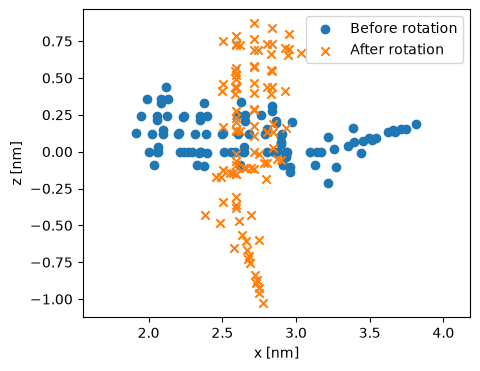

In [4]:
# Rotate the peptide 90 degrees around the Y axis and its own center
rotation = np.array([[0.0, 0.0, 1.0], [0.0, 1.0, 0.0], [-1.0, 0.0, 0.0]])
rotation_center = msm.structure.get_center(molsys, selection=peptide_atom_indices)
before_rotation = msm.pyunitwizard.get_value(
    msm.get(molsys, element='atom', selection=peptide_atom_indices, coordinates=True),
    to_unit='nm').copy()
msm.structure.rotate(
    molsys, selection=peptide_atom_indices, rotation=rotation,
    rotation_center=rotation_center, in_place=True
)

print("Peptide rotated 90 degrees.")
# Compare the actual pose before and after the proper rotation.
import matplotlib.pyplot as plt

after_rotation = msm.pyunitwizard.get_value(
    msm.get(molsys, element='atom', selection=peptide_atom_indices, coordinates=True),
    to_unit='nm')
np.testing.assert_allclose(
    np.linalg.norm(before_rotation[:, :, None] - before_rotation[:, None, :], axis=-1),
    np.linalg.norm(after_rotation[:, :, None] - after_rotation[:, None, :], axis=-1),
    atol=1e-12)
plt.figure(figsize=(5, 4))
plt.scatter(before_rotation[0, :, 0], before_rotation[0, :, 2], label='Before rotation')
plt.scatter(after_rotation[0, :, 0], after_rotation[0, :, 2], label='After rotation', marker='x')
plt.xlabel('x [nm]')
plt.ylabel('z [nm]')
plt.axis('equal')
plt.legend()
plt.show()

--- 

### 🏁 END OF PHASE 5: THE PHYSICS LAB

**Congratulations!** You have mastered the environment and the dynamics of your systems. You can now:
1.  **Manage Boxes** and **PBC**.
2.  **Wrap** and **Unwrap** coordinates.
3.  **Calculate Energies** and **Forces**.
4.  **Minimize** and **Simulate** in OpenMM.
5.  **Translate**, **Rotate**, and **Center** your systems in space.

Your project is physically sound. Now, we enter the final stretch. In **Phase 6: Pipeline Developer**, we will learn how to handle Big Data trajectories and automate your analysis for professional production.